
[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/polsitoooo/Ingenieria-Del-Conocimiento-Tareas/blob/main/Tareas_Ejercicios/Semana9/Ejemplo1_Detector_Baches_MobileNetV2_Colab.ipynb)


# 🛣️ Ejemplo 1 adaptado — Clasificación binaria de baches con MobileNetV2

**Sesión 09-A: Transfer Learning — Feature Extraction**  
**Curso:** IS056B — Ingeniería del Conocimiento  
**Basado en:** Ejemplo 1 (Cats vs Dogs) del notebook proporcionado en clase.

### 🎯 Objetivo
Construir una CNN mediante **Feature Extraction** que reconozca si una foto presenta **una carretera normal** o **una carretera con baches**.

| Aspecto | Configuración |
|:--|:--|
| **Dataset** | [Pothole Detection Dataset — Kaggle](https://www.kaggle.com/datasets/atulyakumar98/pothole-detection-dataset) |
| **Etiquetas** | 0 = Sin baches (`normal`), 1 = Con baches (`potholes`) |
| **Modelo** | MobileNetV2 preentrenado con ImageNet |
| **Enfoque** | Congelar backbone + entrenar clasificador nuevo |
| **Tamaño de entrada** | 224 × 224 × 3 |
| **Salida** | 2 neuronas, `softmax` (igual que el Ejemplo 1) |
| **División** | 70 % entrenamiento, 15 % validación, 15 % prueba |

> **Importante:** este proyecto realiza **clasificación de la imagen completa**, NO dibuja cajas alrededor de los baches. El dataset es pequeño (~681 imágenes): los resultados deben interpretarse como un prototipo académico, no un detector listo para producción.

## ⚙️ Configuración del entorno

**Google Colab:** abre `Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU` (si está disponible). Ejecuta las celdas de arriba hacia abajo. La descarga del dataset y de los pesos de ImageNet requiere conexión a Internet.

In [16]:
# 1. Bibliotecas (similar al notebook original)
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import kagglehub
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (12, 5)

print('✅ TensorFlow:', tf.__version__)
print('🖥️ GPU:', tf.config.list_physical_devices('GPU') or 'No detectada (se puede usar CPU)')

✅ TensorFlow: 2.21.0
🖥️ GPU: No detectada (se puede usar CPU)


---
## 1.1. Cargar y explorar el dataset

En el ejemplo de la clase se usó `tfds.load('cats_vs_dogs')`. Aquí **lo reemplazamos** por `kagglehub.dataset_download(...)`, ya que la fuente es Kaggle. Dentro del dataset hay dos carpetas de imágenes: `normal` y `potholes`.

In [17]:
# Descargar desde Kaggle (dataset público)
DATASET_SLUG = 'atulyakumar98/pothole-detection-dataset'
data_dir = Path(kagglehub.dataset_download(DATASET_SLUG))
print('📂 Dataset descargado en:', data_dir)

# Recorrer carpetas anidadas de forma robusta
EXTENSIONES = {'.jpg', '.jpeg', '.png'}
CLASS_FOLDER_TO_ID = {'normal': 0, 'potholes': 1}
CLASS_NAMES_1 = ['Sin baches', 'Con baches']
NUM_CLASSES_1 = 2

image_paths, image_labels = [], []
for path in sorted(data_dir.rglob('*')):
    if path.is_file() and path.suffix.lower() in EXTENSIONES:
        # Tomar el nombre de la carpeta que contiene la imagen
        folder_name = path.parent.name.lower()
        if folder_name in CLASS_FOLDER_TO_ID:
            image_paths.append(str(path))
            image_labels.append(CLASS_FOLDER_TO_ID[folder_name])

image_paths = np.asarray(image_paths)
image_labels = np.asarray(image_labels, dtype=np.int32)

if len(image_paths) == 0 or len(np.unique(image_labels)) != 2:
    raise RuntimeError(
        'No se encontraron ambas clases normal/potholes. '
        'Revisa la estructura impresa por el dataset de Kaggle.'
    )

print(f'📊 Total de imágenes: {len(image_paths)}')
for clase in range(NUM_CLASSES_1):
    print(f'   {clase} = {CLASS_NAMES_1[clase]}: {(image_labels == clase).sum()} imágenes')

📂 Dataset descargado en: C:\Users\User\.cache\kagglehub\datasets\atulyakumar98\pothole-detection-dataset\versions\4
📊 Total de imágenes: 681
   0 = Sin baches: 352 imágenes
   1 = Con baches: 329 imágenes


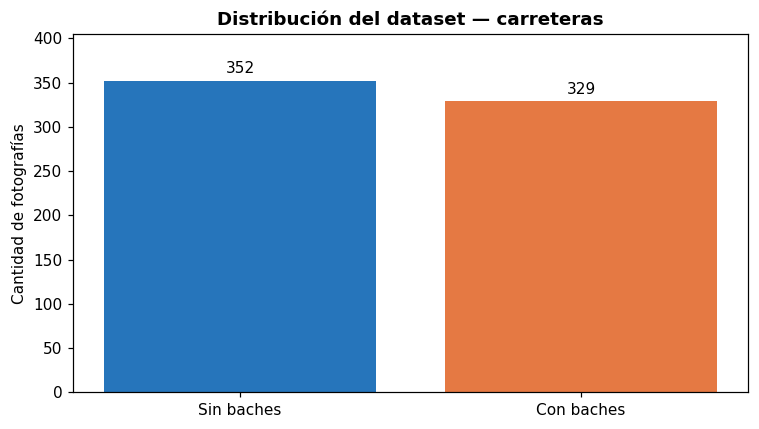

In [18]:
# Gráfico de distribución de imágenes por clase
recuentos = [int(np.sum(image_labels == 0)), int(np.sum(image_labels == 1))]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_NAMES_1, recuentos, color=['#2675BB', '#E57943'])
ax.bar_label(bars, padding=3)
ax.set_title('Distribución del dataset — carreteras', fontweight='bold')
ax.set_ylabel('Cantidad de fotografías')
ax.set_ylim(0, max(recuentos) * 1.15)
plt.tight_layout()
plt.show()

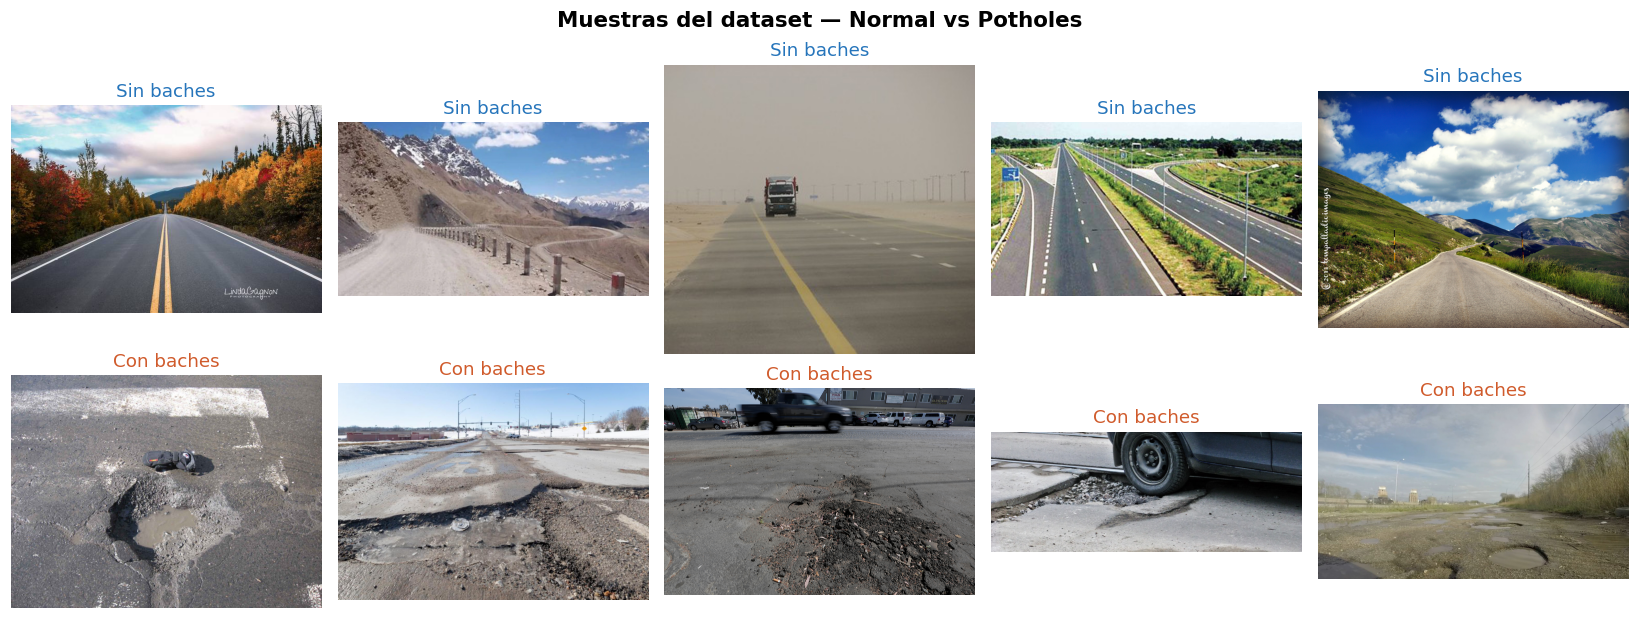

In [19]:
# Mostrar 5 fotografías de cada clase
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
rng = np.random.default_rng(SEED)
for clase in range(NUM_CLASSES_1):
    rutas_clase = image_paths[image_labels == clase]
    elegidas = rng.choice(rutas_clase, size=5, replace=False)
    for j, ruta in enumerate(elegidas):
        with Image.open(ruta) as im:
            axes[clase, j].imshow(im.convert('RGB'))
        axes[clase, j].set_title(CLASS_NAMES_1[clase], color='#2675BB' if clase == 0 else '#D05B2C')
        axes[clase, j].axis('off')
plt.suptitle('Muestras del dataset — Normal vs Potholes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.1.1. División de imágenes (entrenamiento, validación y prueba)

El Ejemplo 1 original usa `train` y `validation`. Aquí agregamos un conjunto **test** independiente para medir el resultado final sin reutilizar los mismos datos durante el entrenamiento. La división es **estratificada**: conserva aproximadamente la proporción de ambas clases.

In [20]:
# 70% train / 15% validation / 15% test, con clases equilibradas proporcionalmente
train_paths, aux_paths, train_labels, aux_labels = train_test_split(
    image_paths, image_labels, test_size=0.30, stratify=image_labels, random_state=SEED
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    aux_paths, aux_labels, test_size=0.50, stratify=aux_labels, random_state=SEED
)

print('📊 Entrenamiento:', len(train_paths))
print('📊 Validación:   ', len(val_paths))
print('📊 Prueba:       ', len(test_paths))
print('📊 Total:        ', len(train_paths) + len(val_paths) + len(test_paths))

# Cargar rutas de imágenes como tensores (estructura similar a tfds.load)
def load_image(path, label):
    content = tf.io.read_file(path)
    image = tf.io.decode_image(content, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return image, label

train_raw = tf.data.Dataset.from_tensor_slices((train_paths, train_labels)).map(
    load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_raw = tf.data.Dataset.from_tensor_slices((val_paths, val_labels)).map(
    load_image, num_parallel_calls=tf.data.AUTOTUNE)
test_raw = tf.data.Dataset.from_tensor_slices((test_paths, test_labels)).map(
    load_image, num_parallel_calls=tf.data.AUTOTUNE)

📊 Entrenamiento: 476
📊 Validación:    102
📊 Prueba:        103
📊 Total:         681


---
## 1.2. Preprocesamiento

Seguimos el **mismo patrón del Ejemplo 1**: redimensionar a `224×224` y aplicar `mobilenet_v2.preprocess_input`, que transforma la escala de píxeles de `[0,255]` a `[-1,1]`. Conservamos `one_hot` porque el clasificador tendrá **dos salidas softmax**.

In [21]:
IMG_SIZE_1 = (224, 224)
BATCH_SIZE = 32

def preprocess_example1(image, label):
    image = tf.image.resize(image, IMG_SIZE_1)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_1)
    return image, label

train_ds_1 = (train_raw
    .shuffle(len(train_paths), seed=SEED, reshuffle_each_iteration=True)
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

val_ds_1 = (val_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

test_ds_1 = (test_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

for imgs, labels in train_ds_1.take(1):
    print('✅ Batch de imágenes:', imgs.shape)
    print('✅ Batch de etiquetas:', labels.shape)
    print('✅ Rango de valores:', f'{imgs.numpy().min():.2f} a {imgs.numpy().max():.2f}')

✅ Batch de imágenes: (32, 224, 224, 3)
✅ Batch de etiquetas: (32, 2)
✅ Rango de valores: -1.00 a 1.00


---
## 1.3. Construir el modelo con Feature Extraction

**Mismos pasos del Ejemplo 1:**
1. Cargar MobileNetV2 con `weights='imagenet'` e `include_top=False`.
2. Congelar su *backbone* con `trainable=False`.
3. Agregar `GlobalAveragePooling2D`, `Dropout` y **Dense(2, softmax)**.

En clasificación binaria también podría utilizarse `Dense(1, sigmoid)`, pero mantenemos `Dense(2, softmax)` para respetar la estructura del ejemplo proporcionado.

In [22]:
# 1. Backbone pre-entrenado, sin su clasificador original
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. CONGELAR las capas del backbone
base_model_1.trainable = False

print('📐 Backbone: MobileNetV2')
print('📐 Capas:', len(base_model_1.layers))
print('📐 Parámetros del backbone:', f'{base_model_1.count_params():,}')
print('📐 Parámetros entrenables del backbone: 0')
print('📐 Forma de salida:', base_model_1.output_shape)

📐 Backbone: MobileNetV2
📐 Capas: 154
📐 Parámetros del backbone: 2,257,984
📐 Parámetros entrenables del backbone: 0
📐 Forma de salida: (None, 7, 7, 1280)


In [23]:
# 3. Nuevo clasificador binario para carreteras
model_1 = models.Sequential([
    base_model_1,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES_1, activation='softmax')
], name='detector_baches_mobilenetv2_FE')

model_1.summary()
total = model_1.count_params()
trainable = sum(int(tf.size(w).numpy()) for w in model_1.trainable_weights)
print(f'\n🔢 Parámetros totales: {total:,}')
print(f'🔓 Parámetros entrenables: {trainable:,} ({100*trainable/total:.2f}%)')
print(f'🔒 Parámetros congelados: {total-trainable:,}')

Model: "detector_baches_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Parámetros totales: 2,260,546
🔓 Parámetros entrenables: 2,562 (0.11%)
🔒 Parámetros congelados: 2,257,984


---
## 1.4. Entrenar y evaluar

El Ejemplo 1 usa **Adam**, `categorical_crossentropy`, `accuracy` y `EarlyStopping`. Aplicaremos lo mismo al nuevo dataset. El número de épocas es un máximo: si el modelo deja de mejorar, se detiene antes.

In [24]:
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True
        )
    ]
)

print(f"\n🏆 Mejor accuracy de validación: {max(history_1.history['val_accuracy']):.2%}")

Epoch 1/8


c:\Users\User\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 515ms/step - accuracy: 0.6996 - loss: 0.6202 - val_accuracy: 0.9020 - val_loss: 0.2917
Epoch 2/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 361ms/step - accuracy: 0.8929 - loss: 0.2723 - val_accuracy: 0.9706 - val_loss: 0.1342
Epoch 3/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 361ms/step - accuracy: 0.9202 - loss: 0.1796 - val_accuracy: 0.9706 - val_loss: 0.0973
Epoch 4/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 344ms/step - accuracy: 0.9433 - loss: 0.1599 - val_accuracy: 0.9804 - val_loss: 0.0786
Epoch 5/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 353ms/step - accuracy: 0.9538 - loss: 0.1300 - val_accuracy: 0.9804 - val_loss: 0.0690
Epoch 6/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 357ms/step - accuracy: 0.9748 - loss: 0.0977 - val_accuracy: 0.9804 - val_loss: 0.0634
Epoch 7/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 358ms/step - accuracy: 0.9706 - loss: 0.0916 - val_accuracy: 0.9804 - val_loss: 0.0599
Epoch 8/8
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 349ms/step - accuracy: 0.9727 - loss: 0.0779 - val_accuracy: 0.9804 - val_loss: 

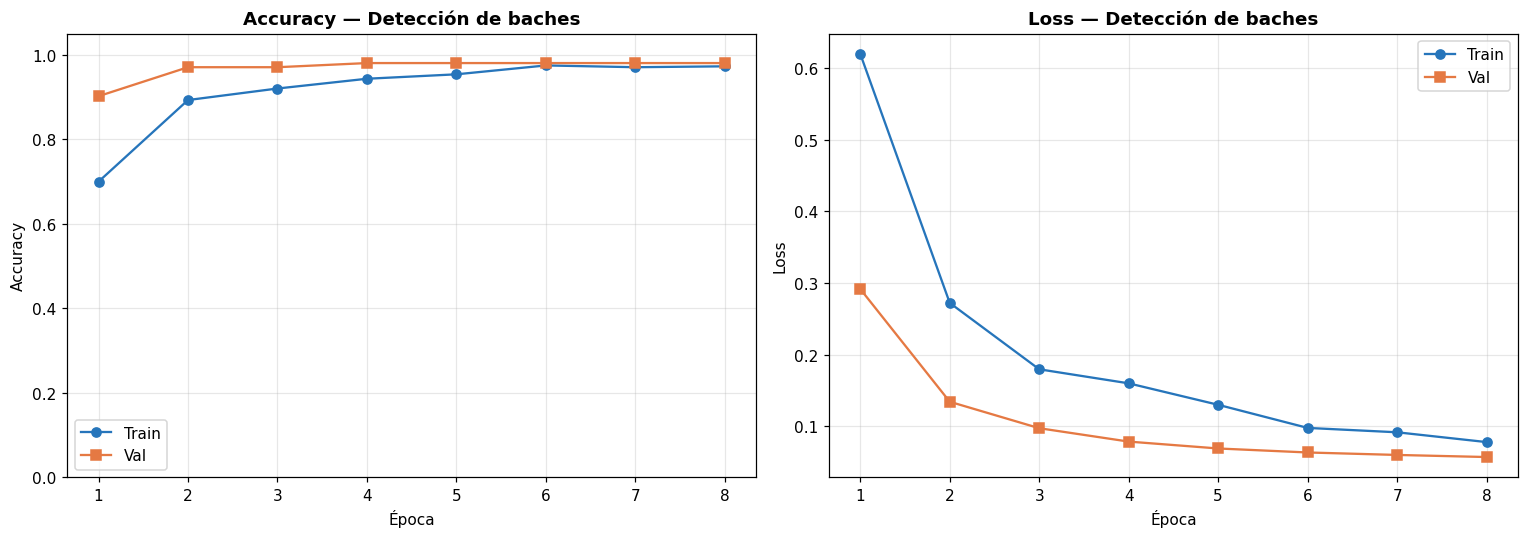

In [25]:
# Curvas del entrenamiento: Accuracy y Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epocas = range(1, len(history_1.history['accuracy']) + 1)

axes[0].plot(epocas, history_1.history['accuracy'], 'o-', label='Train', color='#2675BB')
axes[0].plot(epocas, history_1.history['val_accuracy'], 's-', label='Val', color='#E57943')
axes[0].set_title('Accuracy — Detección de baches', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1.05)
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epocas, history_1.history['loss'], 'o-', label='Train', color='#2675BB')
axes[1].plot(epocas, history_1.history['val_loss'], 's-', label='Val', color='#E57943')
axes[1].set_title('Loss — Detección de baches', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.4.1. Evaluación final con imágenes no vistas (test)

La precisión de **validación** ayuda a elegir el entrenamiento; la de **prueba** permite evaluar las imágenes que no intervinieron en el ajuste. La **matriz de confusión** permite identificar qué tipo de error ocurre: clasificar un bache como normal o lo contrario.

✅ Accuracy final (test): 97.09%
✅ Loss final (test): 0.0581

📋 Reporte de clasificación:
              precision    recall  f1-score   support

  Sin baches       0.98      0.96      0.97        53
  Con baches       0.96      0.98      0.97        50

    accuracy                           0.97       103
   macro avg       0.97      0.97      0.97       103
weighted avg       0.97      0.97      0.97       103



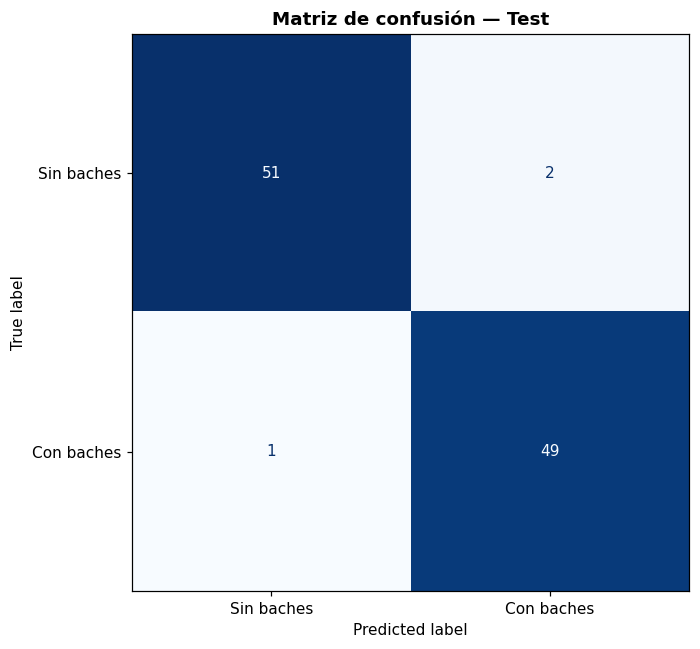

In [26]:
loss_test, accuracy_test = model_1.evaluate(test_ds_1, verbose=0)
print(f'✅ Accuracy final (test): {accuracy_test:.2%}')
print(f'✅ Loss final (test): {loss_test:.4f}')

y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1) for _, labels in test_ds_1
])
probabilidades = model_1.predict(test_ds_1, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

print('\n📋 Reporte de clasificación:')
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=CLASS_NAMES_1, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES_1)
fig, ax = plt.subplots(figsize=(7, 6))
display.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Matriz de confusión — Test', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 1.5. Predicciones visuales

Como en el Ejemplo 1, mostramos **10 imágenes de validación** con la clase real y la clase predicha. El porcentaje es la probabilidad estimada del modelo para esa clase; no garantiza que la predicción sea correcta.

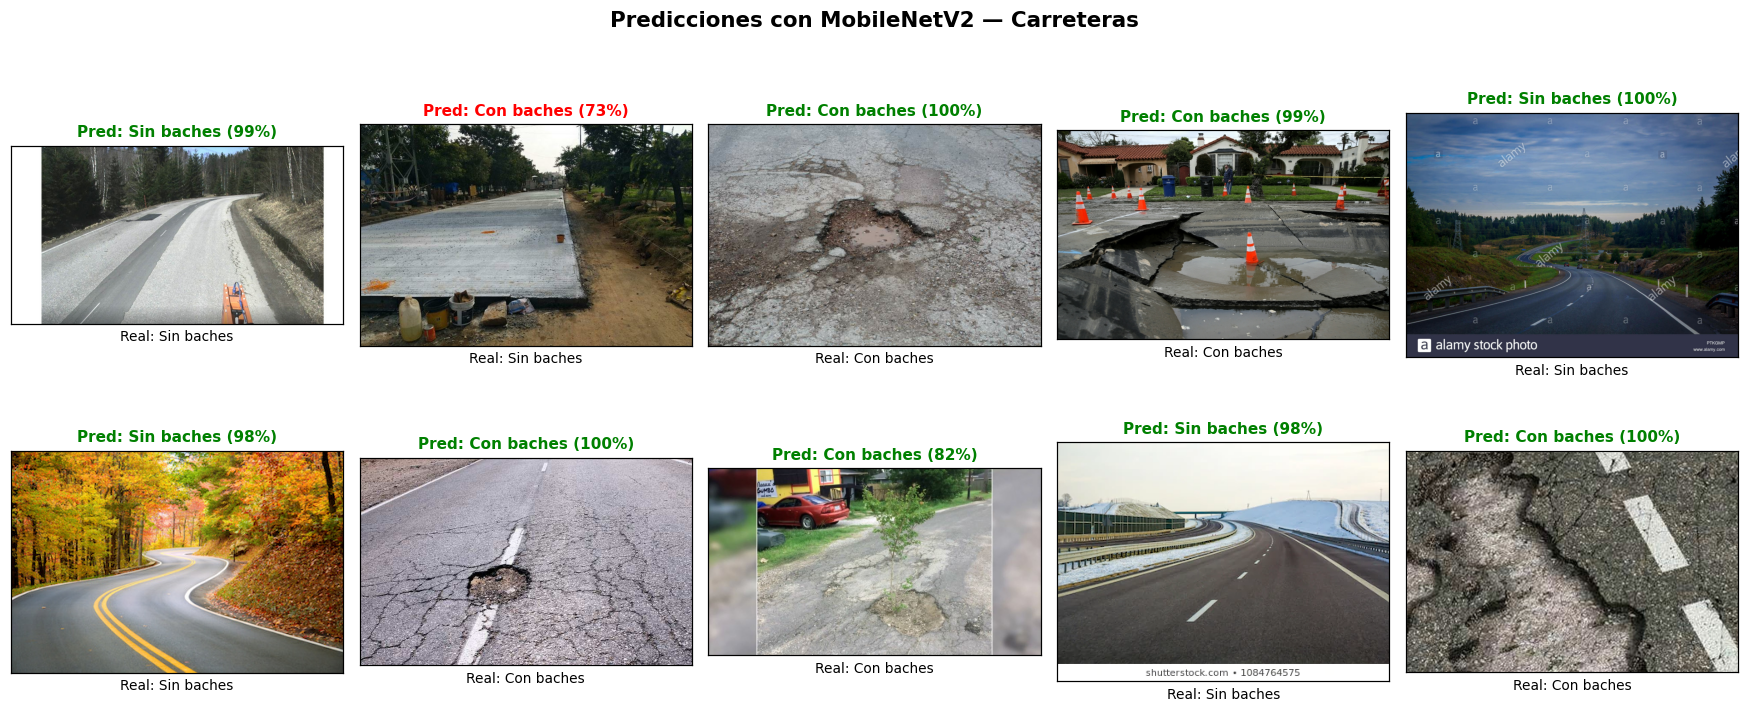

In [27]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, (img, label) in enumerate(val_raw.take(10)):
    ax = axes[i // 5, i % 5]
    # Preprocesamiento consistente con el entrenamiento
    img_prep = tf.image.resize(img, IMG_SIZE_1)
    img_prep = tf.keras.applications.mobilenet_v2.preprocess_input(
        tf.expand_dims(img_prep, 0)
    )
    pred = model_1.predict(img_prep, verbose=0)[0]
    pred_idx = int(np.argmax(pred))
    clase_pred = CLASS_NAMES_1[pred_idx]
    clase_real = CLASS_NAMES_1[int(label.numpy())]
    correcto = clase_pred == clase_real

    ax.imshow(img.numpy())
    ax.set_title(f'Pred: {clase_pred} ({pred[pred_idx]:.0%})',
                 fontsize=10, color='green' if correcto else 'red', fontweight='bold')
    ax.set_xlabel(f'Real: {clase_real}', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Predicciones con MobileNetV2 — Carreteras', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## ✅ Conclusión — Ejemplo 1 adaptado

Al ejecutar el notebook, completa esta tabla con los **resultados reales** (no se inventan métricas antes de entrenar):

| Métrica | Valor |
|:--|:--|
| Dataset | Pothole Detection Dataset (Kaggle) |
| Clases | `normal` (0) y `potholes` (1) |
| Backbone | MobileNetV2 con pesos ImageNet |
| Feature extraction | Backbone congelado; se entrena solo el clasificador |
| Dimensiones de entrada | 224 × 224 × 3 |
| Parámetros nuevos del clasificador | 2,562 (2×1,280 + 2) |
| Épocas realizadas | Consultar `history_1.history` |
| Mejor accuracy de validación | Consultar la salida de 1.4 |
| Accuracy final en test | Consultar la salida de 1.4.1 |

**Interpretación sugerida para la exposición:**

> *Aplicamos transferencia de aprendizaje con MobileNetV2 para clasificar fotografías de carreteras como normales o con baches. Reutilizamos las características aprendidas en ImageNet, congelamos la base convolucional y entrenamos únicamente una capa clasificadora para las dos categorías. Evaluamos el modelo con imágenes separadas de entrenamiento, validación y prueba. Su utilidad inicial es reconocer la posible presencia de baches en una fotografía.*

**Limitaciones:** dataset pequeño; posibles imágenes similares entre divisiones; diferencias de iluminación, perspectiva o calidad; puede fallar con sombras, charcos o grietas. Se recomienda inspección manual de ejemplos y ampliar los datos antes de usarlo para decisiones de mantenimiento vial.

### 🔗 Fuentes
- [Kaggle — Pothole Detection Dataset](https://www.kaggle.com/datasets/atulyakumar98/pothole-detection-dataset)
- [KaggleHub — Descarga oficial con Python](https://github.com/Kaggle/kagglehub)
- [Keras — MobileNetV2](https://keras.io/api/applications/mobilenet/mobilenet_models/)